In [13]:
import sys, tensorflow as tf, cv2, sklearn, mlflow, ultralytics
print("Python      :", sys.version.split()[0])
print("TensorFlow  :", tf.__version__)
print("OpenCV      :", cv2.__version__)
print("scikit-learn:", sklearn.__version__)
print("MLflow      :", mlflow.__version__)
print("Ultralytics :", ultralytics.__version__)
print("GPUs        :", tf.config.list_physical_devices("GPU"))

Python      : 3.12.10
TensorFlow  : 2.21.0
OpenCV      : 5.0.0
scikit-learn: 1.9.1
MLflow      : 3.17.2
Ultralytics : 8.4.183
GPUs        : []


In [14]:
from pathlib import Path
from PIL import Image, UnidentifiedImageError
import pandas as pd
import shutil
from tqdm import tqdm

# If this path is wrong, hardcode it:
# PROJECT_ROOT = Path(r"C:\Users\ycode\Desktop\brain-tumor-project")
PROJECT_ROOT = Path.cwd().parent        # notebook is in notebooks/

RAW_DIR   = PROJECT_ROOT / "data" / "classification" / "raw"
CLEAN_DIR = PROJECT_ROOT / "data" / "classification" / "clean"

VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

print("cwd          :", Path.cwd())
print("RAW_DIR      :", RAW_DIR)
print("RAW_DIR exists:", RAW_DIR.exists())

all_files = [p for p in RAW_DIR.rglob("*") if p.is_file()] if RAW_DIR.exists() else []
print("Total files found:", len(all_files))

assert all_files, (
    f"No files found in {RAW_DIR}.\n"
    "Copy your dataset there (one folder per class) and re-run this cell."
)

print("\nFolders containing files:")
print(pd.Series([p.parent.name for p in all_files]).value_counts())

cwd          : c:\Users\ycode\Desktop\brain-tumor-project\notebooks
RAW_DIR      : c:\Users\ycode\Desktop\brain-tumor-project\data\classification\raw
RAW_DIR exists: True
Total files found: 7023

Folders containing files:
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


In [15]:
records = []

for file in tqdm(all_files, desc="Checking files"):
    status, reason, size = "valid", "", None

    # 1. Extension check
    if file.suffix.lower() not in VALID_EXT:
        status, reason = "invalid", f"bad extension ({file.suffix})"
    else:
        # 2. Integrity check
        try:
            with Image.open(file) as img:
                img.verify()                  # detects truncated/corrupted files
            with Image.open(file) as img:     # reopen: verify() invalidates the object
                img.load()
                size = img.size
        except (UnidentifiedImageError, OSError, ValueError, SyntaxError) as e:
            status, reason = "invalid", f"corrupted ({type(e).__name__})"

    records.append({
        "path": str(file),
        "class": file.parent.name,            # class = name of the parent folder
        "status": status,
        "reason": reason,
        "size": size,
    })

df = pd.DataFrame(records)
print(df["status"].value_counts())
print("\nClasses:", sorted(df["class"].unique()))
df[df["status"] == "invalid"].head(20)

Checking files:   0%|          | 0/7023 [00:00<?, ?it/s]

Checking files: 100%|██████████| 7023/7023 [00:17<00:00, 404.48it/s]

status
valid    7023
Name: count, dtype: int64

Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


,path,class,status,reason,size


In [16]:
import hashlib
import numpy as np

# 1. Hashes: MD5 (exact duplicates) + dHash (near duplicates)
def md5(p):
    return hashlib.md5(open(p, "rb").read()).hexdigest()

def dhash(p, s=16):
    with Image.open(p) as im:
        px = np.asarray(im.convert("L").resize((s + 1, s), Image.LANCZOS), dtype=np.int16)
    return "".join("1" if b else "0" for b in (px[:, 1:] > px[:, :-1]).flatten())

d = df[df["status"] == "valid"].copy().reset_index(drop=True)
d["md5"]   = [md5(p) for p in tqdm(d["path"], desc="MD5")]
d["dhash"] = [dhash(p) for p in tqdm(d["path"], desc="dHash")]

# 2. Remove label conflicts (same image in different classes), then duplicates
for col in ["md5", "dhash"]:
    n_before = len(d)
    conflicts = d.groupby(col)["class"].nunique()
    d = d[~d[col].isin(conflicts[conflicts > 1].index)]
    d = d.drop_duplicates(subset=col, keep="first")
    print(f"{col:6s}: removed {n_before - len(d)}")

final_df = d.reset_index(drop=True)

# 3. Copy to clean/
if CLEAN_DIR.exists():
    shutil.rmtree(CLEAN_DIR)

for i, row in tqdm(final_df.iterrows(), total=len(final_df), desc="Copying"):
    src = Path(row["path"])
    dst = CLEAN_DIR / row["class"] / f"{row['class']}_{i:05d}{src.suffix.lower()}"
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(src, dst)

print("\nFinal:", len(final_df), "images (removed", len(df) - len(final_df), "in total)")
print(final_df["class"].value_counts())

dHash: 100%|██████████| 7023/7023 [00:16<00:00, 428.85it/s]


md5   : removed 297
dhash : removed 257


Copying: 100%|██████████| 6469/6469 [00:29<00:00, 217.81it/s]


Final: 6469 images (removed 554 in total)
class
pituitary     1740
glioma        1620
notumor       1579
meningioma    1530
Name: count, dtype: int64


In [17]:
print("Images per class in clean/:")
for class_dir in sorted(CLEAN_DIR.iterdir()):
    print(f"  {class_dir.name:15s} {len(list(class_dir.glob('*')))}")

print("\nImage size distribution (top 5):")
print(valid_df["size"].value_counts().head())

Images per class in clean/:
  glioma          1620
  meningioma      1530
  notumor         1579
  pituitary       1740

Image size distribution (top 5):
size
(512, 512)    4742
(225, 225)     332
(630, 630)      90
(236, 236)      81
(201, 251)      58
Name: count, dtype: int64


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Build the dataframe first (this part works)
clean_df = pd.DataFrame(
    [(str(p), p.parent.name) for p in CLEAN_DIR.rglob("*") if p.is_file()],
    columns=["path", "class"],
)

# Class names come from the folder names, taken from the dataframe
class_names = sorted(clean_df["class"].unique())
num_classes = len(class_names)

print("Classes     :", class_names)
print("Num classes :", num_classes)
print("\nTotal images:", len(clean_df))
print(clean_df["class"].value_counts())

Classes     : ['glioma', 'meningioma', 'notumor', 'pituitary']
Num classes : 4

Total images: 6469
class
pituitary     1740
glioma        1620
notumor       1579
meningioma    1530
Name: count, dtype: int64


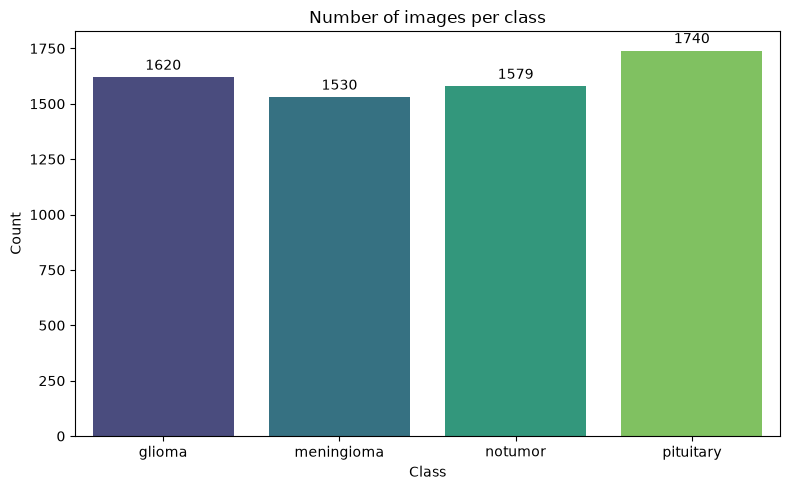

In [19]:
# Countplot
plt.figure(figsize=(8,5))
ax = sns.countplot(data=clean_df, x="class", order=class_names, palette="viridis", hue="class", legend=False)

for container in ax.containers:
    ax.bar_label(container, padding=3)

plt.title("Number of images per class")
plt.xlabel("Class")
plt.ylabel("Count")
plt.tight_layout()

(PROJECT_ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "class_distribution.png", dpi=150)
plt.show()

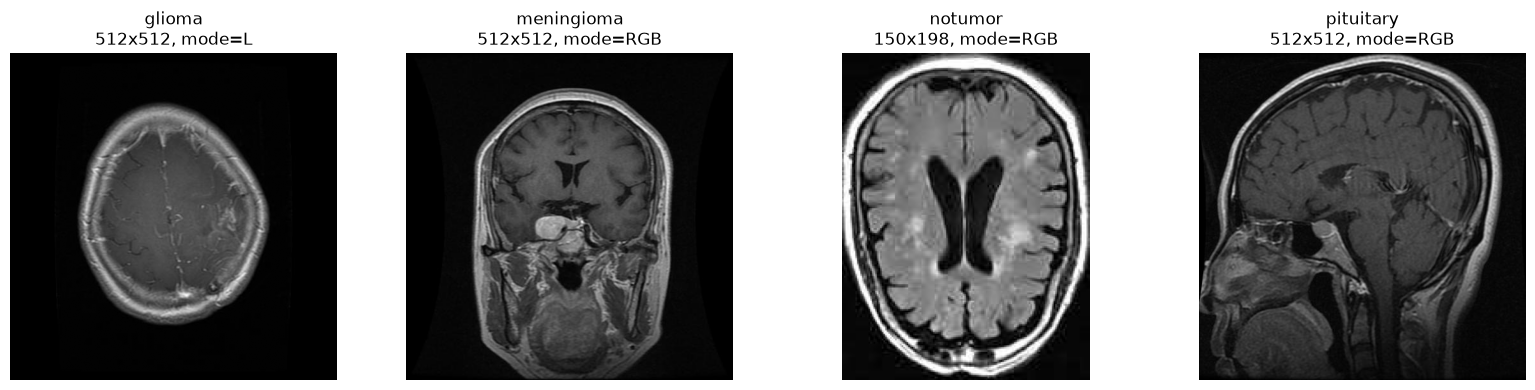

In [20]:
# One sample image per class

fig, axes = plt.subplots(1, num_classes, figsize=(4 * num_classes, 4))

for ax, cls in zip(axes, class_names):
    sample_path = clean_df[clean_df["class"] == cls].sample(1, random_state=42)["path"].iloc[0]
    img = Image.open(sample_path)
    ax.imshow(img, cmap="gray" if img.mode == "L" else None)
    ax.set_title(f"{cls}\n{img.size[0]}x{img.size[1]}, mode={img.mode}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "class_samples.png", dpi=150)
plt.show()

In [21]:
modes = []
for p in tqdm(clean_df["path"].sample(500, random_state=0), desc="Checking modes"):
    with Image.open(p) as im:
        modes.append(im.mode)

print(pd.Series(modes).value_counts())

Checking modes: 100%|██████████| 500/500 [00:00<00:00, 932.23it/s] 

RGB     267
L       232
RGBA      1
Name: count, dtype: int64


Copying test: 100%|██████████| 971/971 [00:02<00:00, 402.27it/s]


            train  val  test
class                       
pituitary    1218  261   261
glioma       1134  243   243
notumor      1105  237   237
meningioma   1071  229   230
TOTAL        4528  970   971


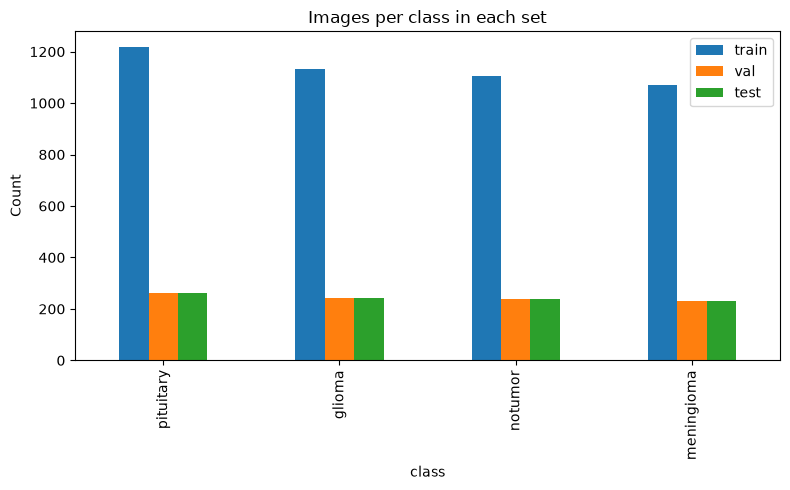

In [22]:
from sklearn.model_selection import train_test_split

SPLIT_DIR = PROJECT_ROOT / "data" / "classification" / "split"

# Rebuild the list of clean images
clean_df = pd.DataFrame(
    [(str(p), p.parent.name) for p in CLEAN_DIR.rglob("*") if p.is_file()],
    columns=["path", "class"],
)

# 70% train, then split the remaining 30% in half -> 15% val, 15% test (stratified)
train_df, temp_df = train_test_split(
    clean_df, test_size=0.30, stratify=clean_df["class"], random_state=42
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["class"], random_state=42
)

# Copy files into split/train, split/val, split/test
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)

for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for _, row in tqdm(part.iterrows(), total=len(part), desc=f"Copying {name}"):
        dst = SPLIT_DIR / name / row["class"] / Path(row["path"]).name
        dst.parent.mkdir(parents=True, exist_ok=True)
        shutil.copy2(row["path"], dst)

# Count and display
counts = pd.DataFrame({
    "train": train_df["class"].value_counts(),
    "val":   val_df["class"].value_counts(),
    "test":  test_df["class"].value_counts(),
}).fillna(0).astype(int)
counts.loc["TOTAL"] = counts.sum()
print(counts)

counts.drop("TOTAL").plot(kind="bar", figsize=(8, 5), title="Images per class in each set")
plt.ylabel("Count")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "split_counts.png", dpi=150)
plt.show()

In [25]:
import random
import numpy as np
from PIL import ImageFilter

random.seed(42)
np.random.seed(42)

TRAIN_DIR = SPLIT_DIR / "train"

# The 3 augmentations
def blur(im):
    return im.filter(ImageFilter.GaussianBlur(radius=random.uniform(0.5, 1.5)))

def noise(im):
    arr = np.asarray(im, dtype=np.float32) + np.random.normal(0, 10, (im.size[1], im.size[0], 3))
    return Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))

def flip(im):
    return im.transpose(Image.FLIP_LEFT_RIGHT)

ops = [blur, noise, flip]

# Bring every class up to the size of the largest one
counts_train = train_df["class"].value_counts()
target = counts_train.max()

for cls, n in counts_train.items():
    originals = list((TRAIN_DIR / cls).glob("*"))
    for i in tqdm(range(target - n), desc=f"Augmenting {cls}"):
        src = random.choice(originals)
        with Image.open(src) as im:
            out = random.choice(ops)(im.convert("RGB"))
        out.save(src.with_name(f"{src.stem}_aug{i}{src.suffix}"))

# Check
print({c: len(list((TRAIN_DIR / c).glob("*"))) for c in class_names})

Augmenting pituitary: 0it [00:00, ?it/s]
Augmenting meningioma: 100%|██████████| 147/147 [00:02<00:00, 73.05it/s]


{'glioma': 1218, 'meningioma': 1218, 'notumor': 1218, 'pituitary': 1218}


In [27]:
import tensorflow as tf
from tensorflow.keras.applications.inception_v3 import preprocess_input

IMG_SIZE = (299, 299)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def load(name, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        SPLIT_DIR / name,
        image_size=IMG_SIZE,
        batch_size=BATCH,
        color_mode="rgb",
        label_mode="categorical",   # one-hot labels
        shuffle=shuffle,            # True for train only
        seed=42,
    )

train_ds = load("train", shuffle=True)
val_ds   = load("val",   shuffle=False)
test_ds  = load("test",  shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)

# Normalize for InceptionV3 (scales pixels to [-1, 1])
def prep(x, y):
    return preprocess_input(x), y

train_ds = train_ds.map(prep, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds   = val_ds.map(prep,   num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds  = test_ds.map(prep,  num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

Found 4872 files belonging to 4 classes.
Found 970 files belonging to 4 classes.
Found 971 files belonging to 4 classes.
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [28]:
from tensorflow.keras import layers, models, optimizers, callbacks

# 1. Load InceptionV3 without its classification head and freeze it
base_model = tf.keras.applications.InceptionV3(
    include_top=False,
    weights="imagenet",
    input_shape=(299, 299, 3),
)
base_model.trainable = False

# 2. New head for our 4 classes
inputs  = layers.Input(shape=(299, 299, 3))
x       = base_model(inputs, training=False)   # keeps BatchNorm in inference mode
x       = layers.GlobalAveragePooling2D()(x)
x       = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = models.Model(inputs, outputs)

# 3. Hyperparameters
LR = 1e-3
model.compile(
    optimizer=optimizers.Adam(learning_rate=LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

# 4. Callbacks
MODELS_DIR = PROJECT_ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

cbs = [
    callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    callbacks.ModelCheckpoint(MODELS_DIR / "inceptionv3_fe.keras", monitor="val_loss", save_best_only=True),
]

model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ inception_v3 (Functional)       │ (None, 8, 8, 2048)     │    21,802,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,810,980 (83.20 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 21,802,784 (83.17 MB)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=cbs
)

#Learning curves
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy")
ax[0].set_xlabel("Epoch")
ax[0].legend()

ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss")
ax[1].set_xlabel("Epoch")
ax[1].legend()

plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "fe_learning_curves.png", dpi=150)
plt.show()